# K-M 复势点力基本解富集 PIKFNN：I–II 混合型中心裂纹（零初始化修正版）

混合载荷采用线弹性奇偶分解，I 型和 II 型分别拥有独立的点力系数和裂尖富集系数：

- `coeffs_i()[-1]` 为 `K_I`；
- `coeffs_ii()[-1]` 为 `K_II`。

两套参数均从零开始，不使用 Ridge warm start。I 型保留原算例的对称边界权重，II 型采用重新平衡后的中心线/裂纹面权重；两套列归一化都与各自实际均方损失一致。


In [1]:
import math
import time
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt


# =========================
# 1) Configuration
# =========================

torch.set_default_dtype(torch.float64)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

cfg = {
    # Geometry and mixed remote loading
    "a": 1.0,
    "b": 2.0,
    "h": 6.0,
    "E": 1.0,
    "nu": 0.30,
    "sigma0": 1.0,
    "tau0": 0.50,
    "plane_strain": True,

    # Boundary collocation
    "n_top": 121,
    "n_side": 121,
    "n_crack": 100,
    "n_ligament": 100,
    "eps_crack": 1.0e-6,

    # Exterior point-force source points
    "n_src_side": 64,
    "src_margin_x_factor": 0.15,
    "src_margin_y_factor": 0.05,

    # Local source cluster below the crack tip
    "tip_cluster_count": 16,
    "tip_cluster_radii": [0.12],
    "tip_cluster_angle_min_deg": 200.0,
    "tip_cluster_angle_max_deg": 340.0,

    # Optimization: zero initialization, no linear warm start
    "adam_steps": 0,
    "adam_lr": 5.0e-2,
    "lbfgs_epochs": 300,
    "lbfgs_max_iter": 20,
    "lambda_reg": 1.0e-10,

    # Boundary weights (mode-specific symmetry/crack balance)
    "w_top": 2.5,
    "w_right": 1.5,
    "w_ligament": 4.0,
    "w_left_i": 2.0,
    "w_crack_i": 8.0,
    "w_left_ii": 4.0,
    "w_crack_ii": 4.0,

    # Plotting
    "nx_plot": 141,
    "ny_plot": 141,
    "seed": 2026,
}

torch.manual_seed(cfg["seed"])
np.random.seed(cfg["seed"])


## 材料参数与混合型参考解

对水平中心裂纹，远场拉伸和远场剪切可以线性叠加。有限宽度修正因子相同，因此分别得到参考 `K_I` 和 `K_II`；参考值只用于验证。


In [2]:
# =========================
# 2) Material constants and references
# =========================

E = cfg["E"]
nu = cfg["nu"]
mu = E / (2.0 * (1.0 + nu))

if cfg["plane_strain"]:
    lam = E * nu / ((1.0 + nu) * (1.0 - 2.0 * nu))
    kappa = 3.0 - 4.0 * nu
else:
    lam = E * nu / (1.0 - nu * nu)
    kappa = (3.0 - nu) / (1.0 + nu)

a = cfg["a"]
b = cfg["b"]
h = cfg["h"]
sigma0 = cfg["sigma0"]
tau0 = cfg["tau0"]


def center_crack_width_factor(a_value: float = a, b_value: float = b) -> float:
    correction = 1.0 - 0.025 * (a_value / b_value) ** 2 + 0.06 * (a_value / b_value) ** 4
    finite_width = math.sqrt(1.0 / math.cos(math.pi * a_value / (2.0 * b_value)))
    return math.sqrt(math.pi * a_value) * correction * finite_width


SIF_FACTOR = center_crack_width_factor()
KI_REF = sigma0 * SIF_FACTOR
KII_REF = tau0 * SIF_FACTOR
MIXITY_REF_DEG = math.degrees(math.atan2(KII_REF, KI_REF))


## 边界配点与域外源点

几何与原 I 型代码一致。I 型和 II 型分量共享同一套边界点及域外点力源，分别施加各自的对称或反对称边界条件。


In [3]:
# =========================
# 3) Geometry and source points
# =========================

def linspace_col(x0: float, x1: float, n: int) -> torch.Tensor:
    return torch.linspace(x0, x1, n, device=device).reshape(-1, 1)


def generate_boundary_points() -> dict[str, torch.Tensor]:
    eps = cfg["eps_crack"]

    x_top = linspace_col(0.0, b, cfg["n_top"])
    top = torch.cat([x_top, torch.full_like(x_top, h)], dim=1)

    y_right = linspace_col(0.0, h, cfg["n_side"])
    right = torch.cat([torch.full_like(y_right, b), y_right], dim=1)

    y_left = linspace_col(0.0, h, cfg["n_side"])
    left = torch.cat([torch.zeros_like(y_left), y_left], dim=1)

    x_crack = linspace_col(0.02 * a, 0.98 * a, cfg["n_crack"])
    crack = torch.cat([x_crack, torch.full_like(x_crack, eps)], dim=1)

    x_ligament = linspace_col(1.02 * a, b, cfg["n_ligament"])
    ligament = torch.cat([x_ligament, torch.zeros_like(x_ligament)], dim=1)

    return {
        "top": top,
        "right": right,
        "left": left,
        "crack": crack,
        "ligament": ligament,
    }


def generate_source_points() -> torch.Tensor:
    mx = cfg["src_margin_x_factor"] * b
    my = cfg["src_margin_y_factor"] * h
    n = cfg["n_src_side"]

    xs = torch.linspace(-mx, b + mx, n, device=device)
    ys = torch.linspace(-my, h + my, n, device=device)

    source_list = []
    for x in xs:
        source_list.append(torch.stack([x, torch.tensor(-my, device=device)]))
        source_list.append(torch.stack([x, torch.tensor(h + my, device=device)]))
    for y in ys[1:-1]:
        source_list.append(torch.stack([torch.tensor(-mx, device=device), y]))
        source_list.append(torch.stack([torch.tensor(b + mx, device=device), y]))

    count = cfg["tip_cluster_count"]
    if count > 0:
        angles = torch.linspace(
            math.radians(cfg["tip_cluster_angle_min_deg"]),
            math.radians(cfg["tip_cluster_angle_max_deg"]),
            count,
            device=device,
        )
        for radius_factor in cfg["tip_cluster_radii"]:
            radius = radius_factor * a
            for theta in angles:
                sx = a + radius * torch.cos(theta)
                sy = radius * torch.sin(theta)
                if sy < -1.0e-8:
                    source_list.append(torch.stack([sx, sy]))

    return torch.stack(source_list, dim=0)


bnd_pts = generate_boundary_points()
src_pts = generate_source_points()


## 源点与边界点分布图

红线是裂纹面；虚线韧带在 I 型分量上采用对称条件，在 II 型分量上采用反对称条件。


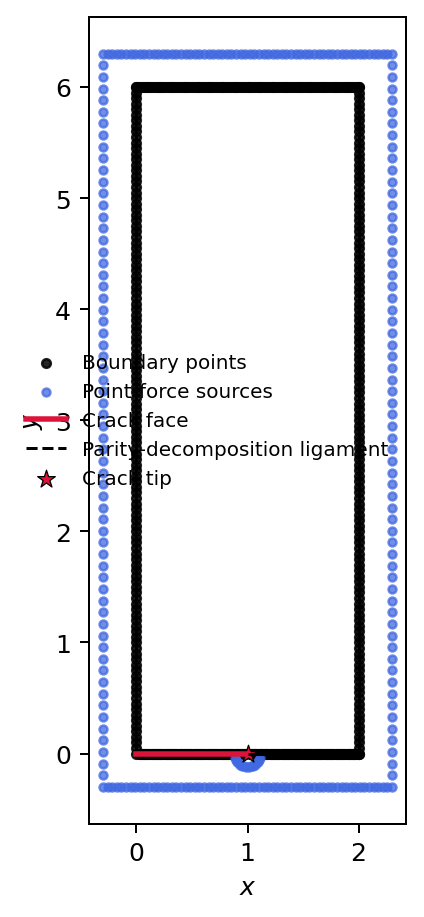

In [4]:
plt.figure(figsize=(5.6, 5.2), dpi=180)
for name, pts in bnd_pts.items():
    plt.scatter(
        pts[:, 0].detach().cpu().numpy(),
        pts[:, 1].detach().cpu().numpy(),
        s=12,
        color="black",
        label="Boundary points" if name == "top" else None,
        alpha=0.85,
    )

plt.scatter(
    src_pts[:, 0].detach().cpu().numpy(),
    src_pts[:, 1].detach().cpu().numpy(),
    s=10,
    color="royalblue",
    label="Point-force sources",
    alpha=0.75,
)

plt.plot([0, b, b, 0, 0], [0, 0, h, h, 0], "k-", lw=1.2)
plt.plot([0, a], [0, 0], color="crimson", lw=2.2, label="Crack face")
plt.plot([a, b], [0, 0], color="black", lw=1.2, ls="--", label="Parity-decomposition ligament")
plt.scatter([a], [0], s=55, marker="*", color="crimson", edgecolor="black", linewidth=0.5, label="Crack tip")
plt.gca().set_aspect("equal", adjustable="box")
plt.xlabel(r"$x$")
plt.ylabel(r"$y$")
plt.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.savefig("km_complex_potential_mixed_mode_sources.png", dpi=600, bbox_inches="tight")
plt.show()


## K-M 位移与应力公式

`km_response()` 与原代码一致：输入 `Phi, Phi', Phi'', Psi, Psi'`，统一输出位移和三个应力分量。


In [5]:
# =========================
# 4) K-M formulas
# =========================

def km_response(
    z: torch.Tensor,
    phi: torch.Tensor,
    dphi: torch.Tensor,
    ddphi: torch.Tensor,
    psi: torch.Tensor,
    dpsi: torch.Tensor,
) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor]:
    stress_sum = 4.0 * torch.real(dphi)
    stress_diff_complex = 2.0 * (torch.conj(z) * ddphi + dpsi)
    stress_diff = torch.real(stress_diff_complex)
    sigma_xy = 0.5 * torch.imag(stress_diff_complex)
    sigma_xx = 0.5 * (stress_sum - stress_diff)
    sigma_yy = 0.5 * (stress_sum + stress_diff)

    displacement_complex = (kappa * phi - z * torch.conj(dphi) - torch.conj(psi)) / (2.0 * mu)
    ux = torch.real(displacement_complex)
    uy = torch.imag(displacement_complex)
    return ux, uy, sigma_xx, sigma_yy, sigma_xy


## 点力复势基本解与 I/II 型裂尖富集

公共背景列由域外点力复势组成；随后分别追加单位 `K_I` 和单位 `K_II` 裂尖列。两个模式共享背景核函数形式，但拥有独立的可训练系数。


In [6]:
# =========================
# 5) Complex-potential basis functions
# =========================

def polynomial_basis_response(
    x: torch.Tensor,
    y: torch.Tensor,
    which: str,
    degree: int,
    coeff: complex,
) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor]:
    z = torch.complex(x.reshape(-1), y.reshape(-1))
    c = torch.as_tensor(coeff, dtype=z.dtype, device=device)

    if degree == 0:
        p = torch.ones_like(z)
        dp = torch.zeros_like(z)
        ddp = torch.zeros_like(z)
    elif degree == 1:
        p = z
        dp = torch.ones_like(z)
        ddp = torch.zeros_like(z)
    elif degree == 2:
        p = z * z
        dp = 2.0 * z
        ddp = 2.0 * torch.ones_like(z)
    else:
        raise ValueError("Only degree 0, 1, 2 are used.")

    zero = torch.zeros_like(z)
    if which == "phi":
        return km_response(z, c * p, c * dp, c * ddp, zero, zero)
    if which == "psi":
        return km_response(z, zero, zero, zero, c * p, c * dp)
    raise ValueError(which)


def complex_point_force_potential_response(
    x: torch.Tensor,
    y: torch.Tensor,
    sx: torch.Tensor,
    sy: torch.Tensor,
    fx: float,
    fy: float,
    add_kelvin_constant: bool = True,
) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor]:
    """Point-force fundamental solution written as K-M complex potentials."""
    z = torch.complex(x.reshape(-1), y.reshape(-1))
    zeta = torch.complex(sx.reshape(()), sy.reshape(()))
    p_force = torch.as_tensor(complex(fx, fy), dtype=z.dtype, device=device)
    q = z - zeta

    den = 2.0 * math.pi * (kappa + 1.0)
    logq = torch.log(q)

    phi = -p_force / den * logq
    dphi = -p_force / den / q
    ddphi = p_force / den / (q * q)

    psi = kappa * torch.conj(p_force) / den * logq + p_force * torch.conj(zeta) / den / q
    dpsi = kappa * torch.conj(p_force) / den / q - p_force * torch.conj(zeta) / den / (q * q)

    if add_kelvin_constant:
        phi = phi + p_force / (2.0 * math.pi * kappa * (kappa + 1.0))

    return km_response(z, phi, dphi, ddphi, psi, dpsi)


def mode_i_tip_response(
    x: torch.Tensor,
    y: torch.Tensor,
) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor]:
    xl = x.reshape(-1) - a
    yl = y.reshape(-1)
    r = torch.sqrt(torch.clamp(xl * xl + yl * yl, min=1.0e-20))
    theta = torch.atan2(yl, xl)

    c2 = torch.cos(0.5 * theta)
    s2 = torch.sin(0.5 * theta)
    s32 = torch.sin(1.5 * theta)
    c32 = torch.cos(1.5 * theta)

    root = torch.sqrt(r / (2.0 * math.pi))
    inv_root = 1.0 / torch.sqrt(2.0 * math.pi * r)

    ux = root * c2 * (kappa - 1.0 + 2.0 * s2 * s2) / (2.0 * mu)
    uy = root * s2 * (kappa + 1.0 - 2.0 * c2 * c2) / (2.0 * mu)
    sigma_xx = inv_root * c2 * (1.0 - s2 * s32)
    sigma_yy = inv_root * c2 * (1.0 + s2 * s32)
    sigma_xy = inv_root * s2 * c2 * c32
    return ux, uy, sigma_xx, sigma_yy, sigma_xy


def mode_ii_tip_response(
    x: torch.Tensor,
    y: torch.Tensor,
) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor]:
    xl = x.reshape(-1) - a
    yl = y.reshape(-1)
    r = torch.sqrt(torch.clamp(xl * xl + yl * yl, min=1.0e-20))
    theta = torch.atan2(yl, xl)

    c2 = torch.cos(0.5 * theta)
    s2 = torch.sin(0.5 * theta)
    c32 = torch.cos(1.5 * theta)
    s32 = torch.sin(1.5 * theta)

    root = torch.sqrt(r / (2.0 * math.pi))
    inv_root = 1.0 / torch.sqrt(2.0 * math.pi * r)

    ux = root * s2 * (kappa + 2.0 + torch.cos(theta)) / (2.0 * mu)
    uy = root * c2 * (kappa - 2.0 + torch.cos(theta)) / (2.0 * mu)
    sigma_xx = -inv_root * s2 * (2.0 + c2 * c32)
    sigma_yy = inv_root * s2 * c2 * c32
    sigma_xy = inv_root * c2 * (1.0 - s2 * s32)
    return ux, uy, sigma_xx, sigma_yy, sigma_xy


def build_common_basis_columns(points: torch.Tensor) -> dict[str, torch.Tensor]:
    """Build point-force response matrices shared by the I and II branches."""
    x = points[:, 0:1]
    y = points[:, 1:2]
    cols: dict[str, list[torch.Tensor]] = {"ux": [], "uy": [], "sxx": [], "syy": [], "sxy": []}

    def add_response(response):
        for name, value in zip(("ux", "uy", "sxx", "syy", "sxy"), response):
            cols[name].append(value.reshape(-1))

    # Low-order K-M polynomial background terms.
    for which in ("phi", "psi"):
        for degree in (0, 1, 2):
            add_response(polynomial_basis_response(x, y, which, degree, 1.0 + 0.0j))
            add_response(polynomial_basis_response(x, y, which, degree, 0.0 + 1.0j))

    for source in src_pts:
        sx, sy = source[0], source[1]
        add_response(complex_point_force_potential_response(x, y, sx, sy, 1.0, 0.0))
        add_response(complex_point_force_potential_response(x, y, sx, sy, 0.0, 1.0))

    return {name: torch.stack(values, dim=1) for name, values in cols.items()}


def append_tip_column(
    common: dict[str, torch.Tensor],
    tip_response: tuple[torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor],
) -> dict[str, torch.Tensor]:
    result = {}
    for name, tip_value in zip(("ux", "uy", "sxx", "syy", "sxy"), tip_response):
        result[name] = torch.cat([common[name], tip_value.reshape(-1, 1)], dim=1)
    return result


## 组装两套模式矩阵并分别归一化

I 型和 II 型分别使用 `sqrt(weight / number_of_points)` 缩放各边界矩阵块，再计算 `col_scale_i` 和 `col_scale_ii`。


In [7]:
# =========================
# 6) Assemble basis matrices and loss-consistent column scaling
# =========================

common_basis = {name: build_common_basis_columns(points) for name, points in bnd_pts.items()}
basis_i = {}
basis_ii = {}
for name, points in bnd_pts.items():
    x = points[:, 0:1]
    y = points[:, 1:2]
    basis_i[name] = append_tip_column(common_basis[name], mode_i_tip_response(x, y))
    basis_ii[name] = append_tip_column(common_basis[name], mode_ii_tip_response(x, y))

n_unknowns = basis_i["top"]["ux"].shape[1]


def mode_equations(mode: str):
    if mode == "I":
        return [
            ("top", "syy", sigma0, cfg["w_top"]),
            ("top", "sxy", 0.0, cfg["w_top"]),
            ("right", "sxx", 0.0, cfg["w_right"]),
            ("right", "sxy", 0.0, cfg["w_right"]),
            ("left", "ux", 0.0, cfg["w_left_i"]),
            ("left", "sxy", 0.0, cfg["w_left_i"]),
            ("crack", "syy", 0.0, cfg["w_crack_i"]),
            ("crack", "sxy", 0.0, cfg["w_crack_i"]),
            ("ligament", "uy", 0.0, cfg["w_ligament"]),
            ("ligament", "sxy", 0.0, cfg["w_ligament"]),
        ]
    if mode == "II":
        return [
            ("top", "syy", 0.0, cfg["w_top"]),
            ("top", "sxy", tau0, cfg["w_top"]),
            ("right", "sxx", 0.0, cfg["w_right"]),
            ("right", "sxy", tau0, cfg["w_right"]),
            ("left", "uy", 0.0, cfg["w_left_ii"]),
            ("left", "sxx", 0.0, cfg["w_left_ii"]),
            ("crack", "syy", 0.0, cfg["w_crack_ii"]),
            ("crack", "sxy", 0.0, cfg["w_crack_ii"]),
            ("ligament", "ux", 0.0, cfg["w_ligament"]),
            ("ligament", "syy", 0.0, cfg["w_ligament"]),
        ]
    raise ValueError(mode)


def compute_column_scale(mode: str) -> torch.Tensor:
    bmat = basis_i if mode == "I" else basis_ii
    blocks = []
    for group, quantity, _, weight in mode_equations(mode):
        block = bmat[group][quantity]
        factor = math.sqrt(weight / block.shape[0])
        blocks.append(factor * block)
    a_scale = torch.cat(blocks, dim=0)
    scale = torch.linalg.norm(a_scale, dim=0).detach()
    return torch.where(scale > 0.0, scale, torch.ones_like(scale))


col_scale_i = compute_column_scale("I")
col_scale_ii = compute_column_scale("II")


## 混合型 PIKFNN 系数模型

`theta_i` 与 `theta_ii` 是两套归一化参数。`coeffs_i()[-1]` 为 `K_I`，`coeffs_ii()[-1]` 为 `K_II`；点力背景系数分别正则化，两个 SIF 不参与正则化。


In [8]:
# =========================
# 7) Mixed-mode PIKFNN coefficient model
# =========================

class KMMixedModeModel(torch.nn.Module):
    def __init__(self, n_terms: int, scale_i: torch.Tensor, scale_ii: torch.Tensor):
        super().__init__()
        self.theta_i = torch.nn.Parameter(torch.zeros(n_terms, 1, device=device))
        self.theta_ii = torch.nn.Parameter(torch.zeros(n_terms, 1, device=device))
        self.register_buffer("col_scale_i", scale_i.reshape(-1, 1).clone())
        self.register_buffer("col_scale_ii", scale_ii.reshape(-1, 1).clone())

    def coeffs_i(self) -> torch.Tensor:
        return self.theta_i / self.col_scale_i

    def coeffs_ii(self) -> torch.Tensor:
        return self.theta_ii / self.col_scale_ii

    def group_quantity(self, mode: str, group: str, quantity: str) -> torch.Tensor:
        if mode == "I":
            return basis_i[group][quantity] @ self.coeffs_i()
        if mode == "II":
            return basis_ii[group][quantity] @ self.coeffs_ii()
        raise ValueError(mode)

    def total_group_quantity(self, group: str, quantity: str) -> torch.Tensor:
        return self.group_quantity("I", group, quantity) + self.group_quantity("II", group, quantity)

    def regularization(self) -> torch.Tensor:
        return torch.mean(self.theta_i[:-1] ** 2) + torch.mean(self.theta_ii[:-1] ** 2)


model = KMMixedModeModel(n_unknowns, col_scale_i, col_scale_ii).to(device)


## I 型与 II 型奇偶边界损失

两个分量分别满足对应的对称条件；外边界载荷分别为 `sigma0` 和 `tau0`。总场自动满足组合远场载荷。


In [9]:
# =========================
# 8) Boundary-condition loss
# =========================

def mode_i_losses(net: KMMixedModeModel) -> tuple[torch.Tensor, dict[str, float]]:
    detail = {}

    syy_top = net.group_quantity("I", "top", "syy")
    sxy_top = net.group_quantity("I", "top", "sxy")
    loss_top = torch.mean((syy_top - sigma0) ** 2) + torch.mean(sxy_top ** 2)

    sxx_right = net.group_quantity("I", "right", "sxx")
    sxy_right = net.group_quantity("I", "right", "sxy")
    loss_right = torch.mean(sxx_right ** 2) + torch.mean(sxy_right ** 2)

    ux_left = net.group_quantity("I", "left", "ux")
    sxy_left = net.group_quantity("I", "left", "sxy")
    loss_left = torch.mean(ux_left ** 2) + torch.mean(sxy_left ** 2)

    syy_crack = net.group_quantity("I", "crack", "syy")
    sxy_crack = net.group_quantity("I", "crack", "sxy")
    loss_crack = torch.mean(syy_crack ** 2) + torch.mean(sxy_crack ** 2)

    uy_lig = net.group_quantity("I", "ligament", "uy")
    sxy_lig = net.group_quantity("I", "ligament", "sxy")
    loss_ligament = torch.mean(uy_lig ** 2) + torch.mean(sxy_lig ** 2)

    detail.update(top=loss_top.detach().item(), right=loss_right.detach().item(),
                  left=loss_left.detach().item(), crack=loss_crack.detach().item(),
                  ligament=loss_ligament.detach().item())

    total = (
        cfg["w_top"] * loss_top
        + cfg["w_right"] * loss_right
        + cfg["w_left_i"] * loss_left
        + cfg["w_crack_i"] * loss_crack
        + cfg["w_ligament"] * loss_ligament
    )
    return total, detail


def mode_ii_losses(net: KMMixedModeModel) -> tuple[torch.Tensor, dict[str, float]]:
    detail = {}

    syy_top = net.group_quantity("II", "top", "syy")
    sxy_top = net.group_quantity("II", "top", "sxy")
    loss_top = torch.mean(syy_top ** 2) + torch.mean((sxy_top - tau0) ** 2)

    sxx_right = net.group_quantity("II", "right", "sxx")
    sxy_right = net.group_quantity("II", "right", "sxy")
    loss_right = torch.mean(sxx_right ** 2) + torch.mean((sxy_right - tau0) ** 2)

    uy_left = net.group_quantity("II", "left", "uy")
    sxx_left = net.group_quantity("II", "left", "sxx")
    loss_left = torch.mean(uy_left ** 2) + torch.mean(sxx_left ** 2)

    syy_crack = net.group_quantity("II", "crack", "syy")
    sxy_crack = net.group_quantity("II", "crack", "sxy")
    loss_crack = torch.mean(syy_crack ** 2) + torch.mean(sxy_crack ** 2)

    ux_lig = net.group_quantity("II", "ligament", "ux")
    syy_lig = net.group_quantity("II", "ligament", "syy")
    loss_ligament = torch.mean(ux_lig ** 2) + torch.mean(syy_lig ** 2)

    detail.update(top=loss_top.detach().item(), right=loss_right.detach().item(),
                  left=loss_left.detach().item(), crack=loss_crack.detach().item(),
                  ligament=loss_ligament.detach().item())

    total = (
        cfg["w_top"] * loss_top
        + cfg["w_right"] * loss_right
        + cfg["w_left_ii"] * loss_left
        + cfg["w_crack_ii"] * loss_crack
        + cfg["w_ligament"] * loss_ligament
    )
    return total, detail


def boundary_group_losses(net: KMMixedModeModel) -> tuple[torch.Tensor, dict[str, float]]:
    loss_i, detail_i = mode_i_losses(net)
    loss_ii, detail_ii = mode_ii_losses(net)
    loss_reg = cfg["lambda_reg"] * net.regularization()
    total = loss_i + loss_ii + loss_reg

    detail = {f"I_{key}": value for key, value in detail_i.items()}
    detail.update({f"II_{key}": value for key, value in detail_ii.items()})
    detail["reg"] = loss_reg.detach().item()
    detail["total"] = total.detach().item()
    return total, detail


## 两套系数均从零开始优化

训练开始前不求解线性系统，也不把参考值或最小二乘解写入 `theta_i`、`theta_ii`。训练后的线性解仅用于矩阵诊断。


In [10]:
# =========================
# 9) Zero-initialized Adam + L-BFGS optimization
# =========================

def train_model() -> list[float]:
    history: list[float] = []
    t0 = time.time()

    optimizer_adam = torch.optim.Adam(model.parameters(), lr=cfg["adam_lr"])
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer_adam, mode="min", factor=0.5, patience=100, min_lr=1.0e-5)

    print("\nStage 1: Adam")
    for epoch in range(cfg["adam_steps"]):
        optimizer_adam.zero_grad()
        total, detail = boundary_group_losses(model)
        total.backward()
        optimizer_adam.step()
        scheduler.step(total.detach())
        history.append(total.item())
        if (epoch + 1) % 100 == 0 or epoch == 0:
            print(f"Adam [{epoch+1:5d}/{cfg['adam_steps']}] total={total.item():.4e} | KI={model.coeffs_i()[-1].item():.8f}, KII={model.coeffs_ii()[-1].item():.8f}")

    if cfg["lbfgs_epochs"] > 0:
        optimizer_lbfgs = torch.optim.LBFGS(model.parameters(), lr=1.0, max_iter=cfg["lbfgs_max_iter"], max_eval=cfg["lbfgs_max_iter"] + 10, tolerance_grad=1.0e-12, tolerance_change=1.0e-14, history_size=100, line_search_fn="strong_wolfe")
        print("\nStage 2: L-BFGS")
        for epoch in range(cfg["lbfgs_epochs"]):
            def closure():
                optimizer_lbfgs.zero_grad()
                total, _ = boundary_group_losses(model)
                total.backward()
                return total
            optimizer_lbfgs.step(closure)
            total, detail = boundary_group_losses(model)
            history.append(total.item())
            if (epoch + 1) % 10 == 0 or epoch == 0:
                print(f"LBFGS [{epoch+1:5d}/{cfg['lbfgs_epochs']}] total={total.item():.4e} | KI={model.coeffs_i()[-1].item():.8f}, KII={model.coeffs_ii()[-1].item():.8f} | I-crack={detail['I_crack']:.2e}, II-crack={detail['II_crack']:.2e}")

    print(f"\nTraining time: {time.time()-t0:.2f} s")
    if history:
        plt.figure(figsize=(5.4, 3.6), dpi=180)
        plt.semilogy(history, lw=1.5)
        plt.xlabel("optimizer record")
        plt.ylabel("weighted mixed-mode boundary loss")
        plt.grid(True, alpha=0.25)
        plt.tight_layout()
        plt.savefig("km_complex_potential_mixed_mode_loss_history.png", dpi=600, bbox_inches="tight")
        plt.close()
    return history


def direct_least_squares_check(mode: str) -> tuple[float, int, tuple[int, int]]:
    bmat = basis_i if mode == "I" else basis_ii
    scale = col_scale_i if mode == "I" else col_scale_ii
    rows, rhs = [], []
    for group, quantity, target, weight in mode_equations(mode):
        block = bmat[group][quantity]
        factor = math.sqrt(weight / block.shape[0])
        rows.append(factor * block / scale.reshape(1, -1))
        rhs.append(factor * torch.full((block.shape[0], 1), float(target), device=device))
    amat = torch.cat(rows, dim=0)
    bvec = torch.cat(rhs, dim=0)
    reg = torch.eye(amat.shape[1], device=device)
    reg[-1, -1] = 0.0
    alpha = cfg["lambda_reg"] / max(amat.shape[1] - 1, 1)
    theta = torch.linalg.solve(amat.T @ amat + alpha * reg, amat.T @ bvec)
    coeff = theta / scale.reshape(-1, 1)
    rank = int(torch.linalg.matrix_rank(amat).item())
    return coeff[-1].item(), rank, tuple(amat.shape)


## 训练并输出 `K_I`、`K_II` 与模态混合角

训练值来自全零初始化的 Adam/L-BFGS 流程。训练后的直接线性解仅作为诊断对照。


In [11]:
# =========================
# 10) Diagnostics
# =========================

train_model()
KI_pred = model.coeffs_i()[-1].detach().item()
KII_pred = model.coeffs_ii()[-1].detach().item()
KI_ls, rank_i, shape_i = direct_least_squares_check("I")
KII_ls, rank_ii, shape_ii = direct_least_squares_check("II")

mixity_pred_deg = math.degrees(math.atan2(KII_pred, KI_pred))
rel_err_ki = abs(KI_pred - KI_REF) / abs(KI_REF)
rel_err_kii = abs(KII_pred - KII_REF) / abs(KII_REF)
total, detail = boundary_group_losses(model)

print("\n=== Mixed-mode center-crack result ===")
print(f"K_I predicted   : {KI_pred:.10f}")
print(f"K_I reference   : {KI_REF:.10f}")
print(f"K_I rel. error  : {rel_err_ki:.6%}")
print(f"K_II predicted  : {KII_pred:.10f}")
print(f"K_II reference  : {KII_REF:.10f}")
print(f"K_II rel. error : {rel_err_kii:.6%}")
print(f"mixity predicted: {mixity_pred_deg:.6f} deg")
print(f"mixity reference: {MIXITY_REF_DEG:.6f} deg")
print(f"post-training LS: K_I={KI_ls:.10f}, K_II={KII_ls:.10f}")
print(f"matrix I shape/rank : {shape_i} / {rank_i}")
print(f"matrix II shape/rank: {shape_ii} / {rank_ii}")
print(f"final loss       : {total.item():.6e}")

print("\nSelected boundary loss groups:")
for key in ["I_top","I_left","I_crack","I_ligament","II_top","II_left","II_crack","II_ligament","reg","total"]:
    print(f"  {key:13s}: {detail[key]:.6e}")

result_text = "\n".join([
    "K-M complex-potential point-force PIKFNN mixed-mode result",
    "Initialization    : all-zero coefficients",
    "Warm start        : disabled",
    f"K_I predicted     : {KI_pred:.10f}",
    f"K_I reference     : {KI_REF:.10f}",
    f"K_I rel. error    : {rel_err_ki:.6%}",
    f"K_II predicted    : {KII_pred:.10f}",
    f"K_II reference    : {KII_REF:.10f}",
    f"K_II rel. error   : {rel_err_kii:.6%}",
    f"mixity predicted  : {mixity_pred_deg:.6f} deg",
    f"mixity reference  : {MIXITY_REF_DEG:.6f} deg",
    f"post-training LS  : K_I={KI_ls:.10f}, K_II={KII_ls:.10f}",
    f"matrix I shape/rank : {shape_i} / {rank_i}",
    f"matrix II shape/rank: {shape_ii} / {rank_ii}",
    f"final loss        : {total.item():.6e}",
])
Path("km_complex_potential_mixed_mode_zero_init_result.txt").write_text(result_text + "\n", encoding="utf-8")



Stage 1: Adam

Stage 2: L-BFGS
LBFGS [    1/300] total=1.1431e-01 | KI=0.04359763, KII=0.17567206 | I-crack=2.22e-04, II-crack=1.91e-03
LBFGS [   10/300] total=9.8035e-04 | KI=2.04073215, KII=1.03369771 | I-crack=1.12e-05, II-crack=3.83e-05
LBFGS [   20/300] total=5.3075e-04 | KI=2.12213916, KII=1.04434435 | I-crack=1.41e-06, II-crack=3.74e-05
LBFGS [   30/300] total=4.1113e-04 | KI=2.12852391, KII=1.05471493 | I-crack=4.66e-07, II-crack=2.68e-05
LBFGS [   40/300] total=3.5350e-04 | KI=2.12767429, KII=1.06037916 | I-crack=1.24e-07, II-crack=2.34e-05
LBFGS [   50/300] total=3.2491e-04 | KI=2.12733847, KII=1.05958777 | I-crack=1.09e-07, II-crack=2.20e-05
LBFGS [   60/300] total=2.9809e-04 | KI=2.13119326, KII=1.05219189 | I-crack=6.75e-08, II-crack=2.16e-05
LBFGS [   70/300] total=2.7804e-04 | KI=2.12997413, KII=1.04435792 | I-crack=8.66e-08, II-crack=2.02e-05
LBFGS [   80/300] total=2.5973e-04 | KI=2.13133724, KII=1.04338597 | I-crack=7.94e-08, II-crack=1.77e-05
LBFGS [   90/300] total

559

## 总场评估

评估时先将两套点力背景系数相加，再加入 `K_I` 与 `K_II` 两个裂尖列，从而避免重复存储公共背景矩阵。


In [12]:
def evaluate_total_quantities(points: torch.Tensor, batch_size: int = 2500) -> dict[str, np.ndarray]:
    coeff_i = model.coeffs_i().detach()
    coeff_ii = model.coeffs_ii().detach()
    background_coeff = coeff_i[:-1] + coeff_ii[:-1]
    ki_value = coeff_i[-1]
    kii_value = coeff_ii[-1]

    outs: dict[str, list[torch.Tensor]] = {"ux": [], "uy": [], "sxx": [], "syy": [], "sxy": []}
    for i in range(0, points.shape[0], batch_size):
        batch = points[i:i + batch_size]
        x = batch[:, 0:1]
        y = batch[:, 1:2]
        common = build_common_basis_columns(batch)
        tip_i = mode_i_tip_response(x, y)
        tip_ii = mode_ii_tip_response(x, y)

        for name, value_i, value_ii in zip(("ux", "uy", "sxx", "syy", "sxy"), tip_i, tip_ii):
            value = common[name] @ background_coeff + value_i.reshape(-1, 1) * ki_value + value_ii.reshape(-1, 1) * kii_value
            outs[name].append(value.detach().cpu())

    return {quantity: torch.cat(values, dim=0).numpy().reshape(-1) for quantity, values in outs.items()}


x_plot = torch.linspace(0.0, b, cfg["nx_plot"], device=device)
y_plot = torch.linspace(0.0, h, cfg["ny_plot"], device=device)
X, Y = torch.meshgrid(x_plot, y_plot, indexing="xy")
xy_grid = torch.stack([X.reshape(-1), Y.reshape(-1)], dim=1)

fields = evaluate_total_quantities(xy_grid)
sxx_grid = fields["sxx"].reshape(cfg["ny_plot"], cfg["nx_plot"])
syy_grid = fields["syy"].reshape(cfg["ny_plot"], cfg["nx_plot"])
sxy_grid = fields["sxy"].reshape(cfg["ny_plot"], cfg["nx_plot"])
ux_grid = fields["ux"].reshape(cfg["ny_plot"], cfg["nx_plot"])
uy_grid = fields["uy"].reshape(cfg["ny_plot"], cfg["nx_plot"])

X_np = X.detach().cpu().numpy()
Y_np = Y.detach().cpu().numpy()


## 混合型总应力云图

图中显示 I 型与 II 型叠加后的总应力。裂尖附近小圆区域被屏蔽，以避免奇异值主导色标。


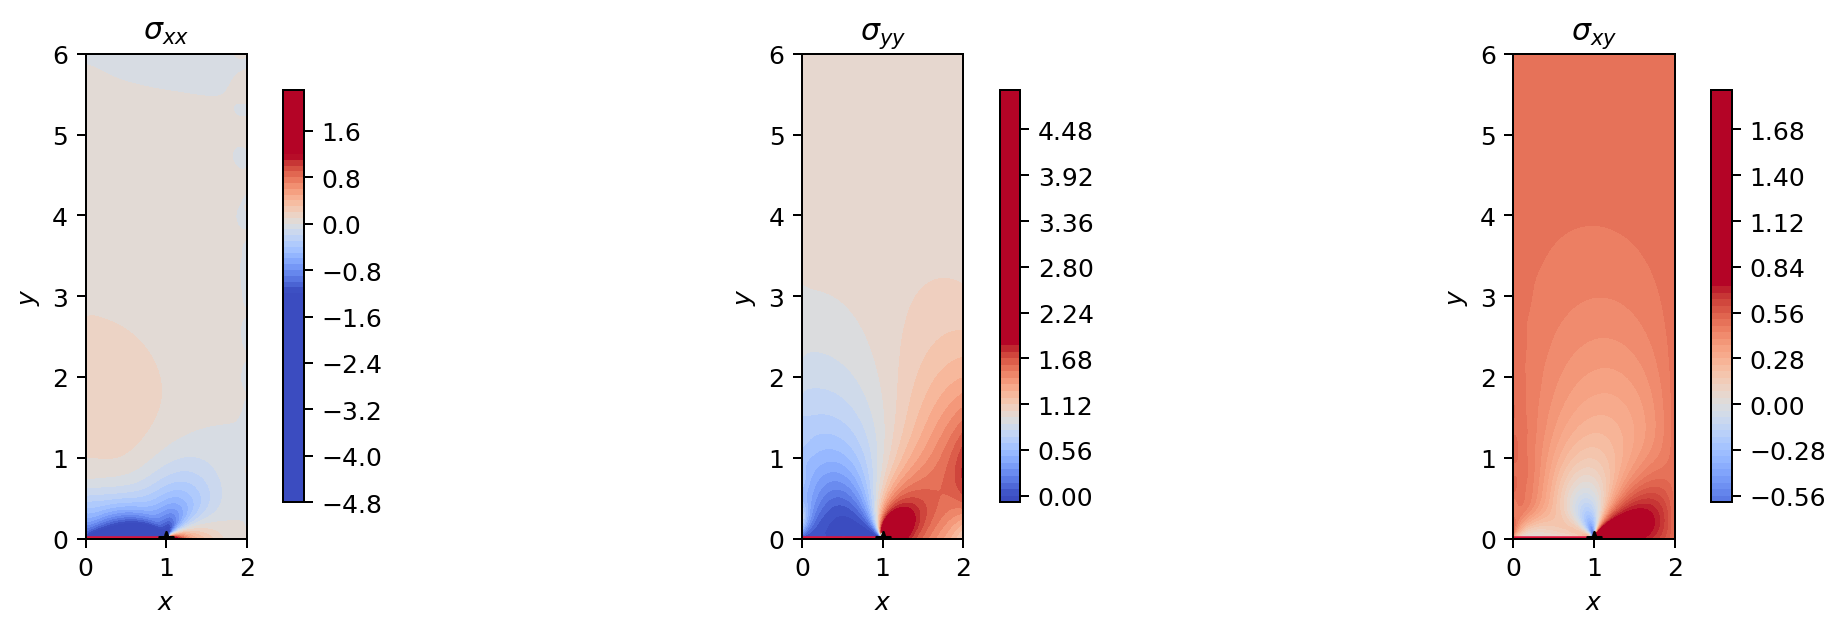

In [13]:
r_tip = np.sqrt((X_np - a)**2 + Y_np**2)
tip_mask = r_tip < 0.05 * a

plot_fields = []
for field in [sxx_grid, syy_grid, sxy_grid]:
    f = field.copy()
    f[tip_mask] = np.nan
    plot_fields.append(f)

fig, axes = plt.subplots(1, 3, figsize=(12.0, 3.4), dpi=180, constrained_layout=True)
plot_data = [
    (plot_fields[0], r"$\sigma_{xx}$", "symmetric"),
    (plot_fields[1], r"$\sigma_{yy}$", "normal"),
    (plot_fields[2], r"$\sigma_{xy}$", "symmetric"),
]

for ax, (data, title, scale_type) in zip(axes, plot_data):
    if scale_type == "symmetric":
        vmax = np.nanpercentile(np.abs(data), 98.5)
        vmin = -vmax
    else:
        vmin = np.nanpercentile(data, 1.0)
        vmax = np.nanpercentile(data, 99.0)

    im = ax.contourf(X_np, Y_np, data, levels=80, cmap="coolwarm", vmin=vmin, vmax=vmax)
    ax.plot([0, a], [0, 0], color="crimson", lw=2.2)
    ax.plot([a, b], [0, 0], color="black", lw=1.2, ls="--")
    ax.scatter([a], [0], s=35, marker="*", color="black", zorder=5)
    ax.set_aspect("equal", adjustable="box")
    ax.set_title(title)
    ax.set_xlabel(r"$x$")
    ax.set_ylabel(r"$y$")
    fig.colorbar(im, ax=ax, shrink=0.85)

plt.savefig("km_complex_potential_mixed_mode_stress_contours.png", dpi=600, bbox_inches="tight")
plt.show()
